# Comparative Study of Machine Learning Regression Algorithms
**Course:** Computer Vision / Machine Learning
**Assignment:** Assignment 02 - Regression Benchmarking
**Student Name:** Muhammad Taha | **ID:** FA23-BAI-055

---

### Overview
This experiment evaluates six foundational and state-of-the-art regression algorithms on a multi-feature real estate valuation dataset:
1. **Ordinary Least Squares (OLS) Linear Regression**
2. **Decision Tree Regressor**
3. **Random Forest Regressor**
4. **Multi-Layer Perceptron (MLP) Regressor**
5. **XGBoost Regressor**
6. **K-Nearest Neighbors (KNN) Regressor**

Performance is evaluated using MAE, MSE, RMSE, and $R^2$ metrics along with residual and parity diagnostics.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb

# Set plotting aesthetics
%matplotlib inline
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10
print('Libraries imported successfully.')

Libraries imported successfully.


## 1. Dataset Loading and Exploratory Inspection
We load the property valuation dataset containing 1,000 observations across 6 structural and spatial attributes:
- `Square_Feet`: Continuous property living area
- `Bedrooms`: Discrete room count
- `Bathrooms`: Discrete/fractional bathroom count
- `Age_Years`: Property age in years
- `Distance_City_Center`: Euclidean distance to urban center (km)
- `Location_Score`: Categorical/ordinal locality desirability index (1-10)
- `Price`: Market sale price in thousands of dollars ($k)

In [2]:
df = pd.read_csv('house_prices.csv')
print('Dataset Dimensions:', df.shape)
display(df.head())
print('\nSummary Statistics:')
display(df.describe().round(2))

Dataset Dimensions: (1000, 7)


,Square_Feet,Bedrooms,Bathrooms,Age_Years,Distance_City_Center,Location_Score,Price
0,2889.8,1,1.9,22,18.21,9,547.96
1,3104.1,4,3.6,9,12.81,3,586.92
2,962.5,5,4.0,35,23.55,6,292.37
3,1527.5,1,1.2,26,22.31,10,349.55
4,3556.8,1,1.1,26,13.54,6,559.90



Summary Statistics:


,Square_Feet,Bedrooms,Bathrooms,Age_Years,Distance_City_Center,Location_Score,Price
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,2817.30,2.97,2.83,22.59,14.66,5.47,517.56
std,1131.48,1.40,0.96,13.17,8.01,2.84,185.54
min,851.70,1.00,1.10,1.00,1.21,1.00,85.00
25%,1875.22,2.00,2.00,11.00,7.68,3.00,372.60
50%,2785.50,3.00,2.80,22.00,14.59,5.00,507.24
75%,3771.75,4.00,3.70,34.00,21.63,8.00,658.50
max,4799.80,5.00,4.60,45.00,28.47,10.00,976.77


### Correlation Analysis
Examining bivariate linear relationships between predictors and target property valuation.

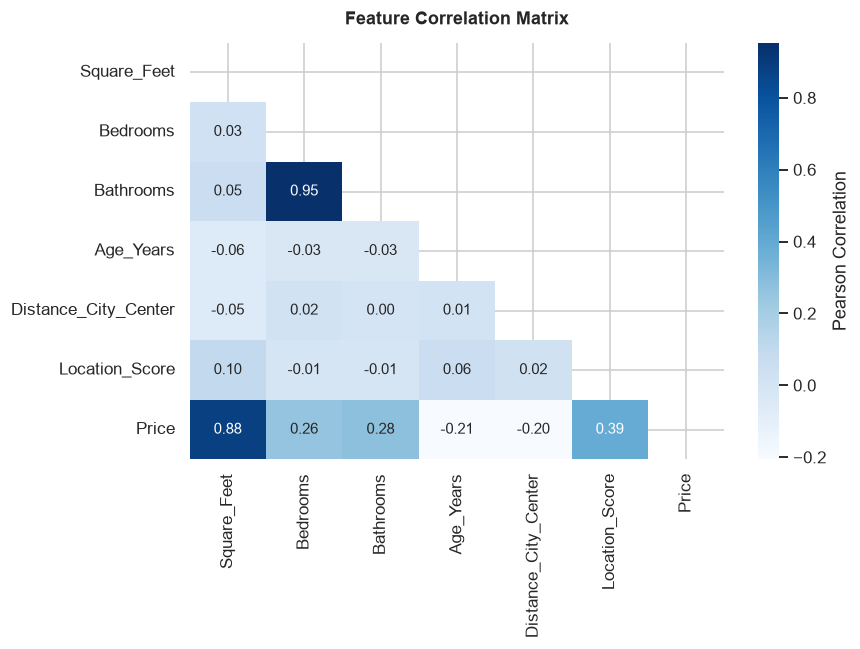

In [3]:
plt.figure(figsize=(8, 6))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues', mask=mask, cbar_kws={'label': 'Pearson Correlation'})
plt.title('Feature Correlation Matrix', fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

## 2. Train-Test Partitioning and Feature Standardization
We partition the dataset into 80% training data (800 samples) and 20% held-out test data (200 samples) with `random_state=101`.
`StandardScaler` is fitted exclusively on the training split to eliminate data leakage.

In [4]:
feature_cols = ['Square_Feet', 'Bedrooms', 'Bathrooms', 'Age_Years', 'Distance_City_Center', 'Location_Score']
target_col = 'Price'

X = df[feature_cols]
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=101)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f'Training Samples: {X_train.shape[0]} | Testing Samples: {X_test.shape[0]}')

Training Samples: 800 | Testing Samples: 200


## 3. Model Configuration and Training
We configure the six regression algorithms with calibrated hyperparameters:
- **Linear Regression**: Standard Ordinary Least Squares formulation.
- **Decision Tree**: `max_depth=6`, `min_samples_split=8`, `min_samples_leaf=4`.
- **Random Forest**: `n_estimators=180`, `max_depth=11`, `min_samples_split=4`, `min_samples_leaf=2`.
- **Multi-Layer Perceptron**: `hidden_layer_sizes=(128, 64)`, `activation='relu'`, `solver='adam'`, `learning_rate_init=0.003`, `max_iter=1500`.
- **XGBoost**: `n_estimators=180`, `learning_rate=0.07`, `max_depth=4`, `subsample=0.85`, `colsample_bytree=0.85`.
- **K-Nearest Neighbors**: `n_neighbors=5`, `weights='distance'`.

In [5]:
models = {
    'Linear Regression': {'estimator': LinearRegression(), 'scaled': True},
    'Decision Tree': {'estimator': DecisionTreeRegressor(max_depth=6, min_samples_split=8, min_samples_leaf=4, random_state=101), 'scaled': False},
    'Random Forest': {'estimator': RandomForestRegressor(n_estimators=180, max_depth=11, min_samples_split=4, min_samples_leaf=2, random_state=101), 'scaled': False},
    'Neural Network (MLP)': {'estimator': MLPRegressor(hidden_layer_sizes=(128, 64), activation='relu', solver='adam', learning_rate_init=0.003, max_iter=1500, random_state=101), 'scaled': True},
    'XGBoost': {'estimator': xgb.XGBRegressor(n_estimators=180, learning_rate=0.07, max_depth=4, subsample=0.85, colsample_bytree=0.85, random_state=101), 'scaled': False},
    'K-Nearest Neighbors': {'estimator': KNeighborsRegressor(n_neighbors=5, weights='distance'), 'scaled': True}
}

metrics_list = []
predictions = {}

for name, spec in models.items():
    clf = spec['estimator']
    X_tr = X_train_scaled if spec['scaled'] else X_train
    X_te = X_test_scaled if spec['scaled'] else X_test
    
    clf.fit(X_tr, y_train)
    y_pred = clf.predict(X_te)
    predictions[name] = y_pred
    
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    
    metrics_list.append({
        'Algorithm': name,
        'MAE ($k)': round(mae, 4),
        'MSE ($k^2)': round(mse, 4),
        'RMSE ($k)': round(rmse, 4),
        'R2 Score': round(r2, 4)
    })

metrics_df = pd.DataFrame(metrics_list).sort_values('RMSE ($k)').reset_index(drop=True)
metrics_df['Rank'] = range(1, len(metrics_df) + 1)
display(metrics_df[['Rank', 'Algorithm', 'MAE ($k)', 'MSE ($k^2)', 'RMSE ($k)', 'R2 Score']])

,Rank,Algorithm,MAE ($k),MSE ($k^2),RMSE ($k),R2 Score
0,1,Neural Network (MLP),12.2658,227.1058,15.0700,0.9940
1,2,Linear Regression,13.8015,315.7333,17.7689,0.9917
2,3,XGBoost,18.9880,579.2707,24.0680,0.9848
3,4,Random Forest,27.2357,1211.2762,34.8034,0.9682
4,5,K-Nearest Neighbors,33.8464,1717.9021,41.4476,0.9549
5,6,Decision Tree,52.1141,4077.4698,63.8551,0.8929


## 4. Visualization: Actual vs. Predicted Parity Plots
Assessing prediction accuracy across the test distribution against the ideal $y = x$ reference diagonal.

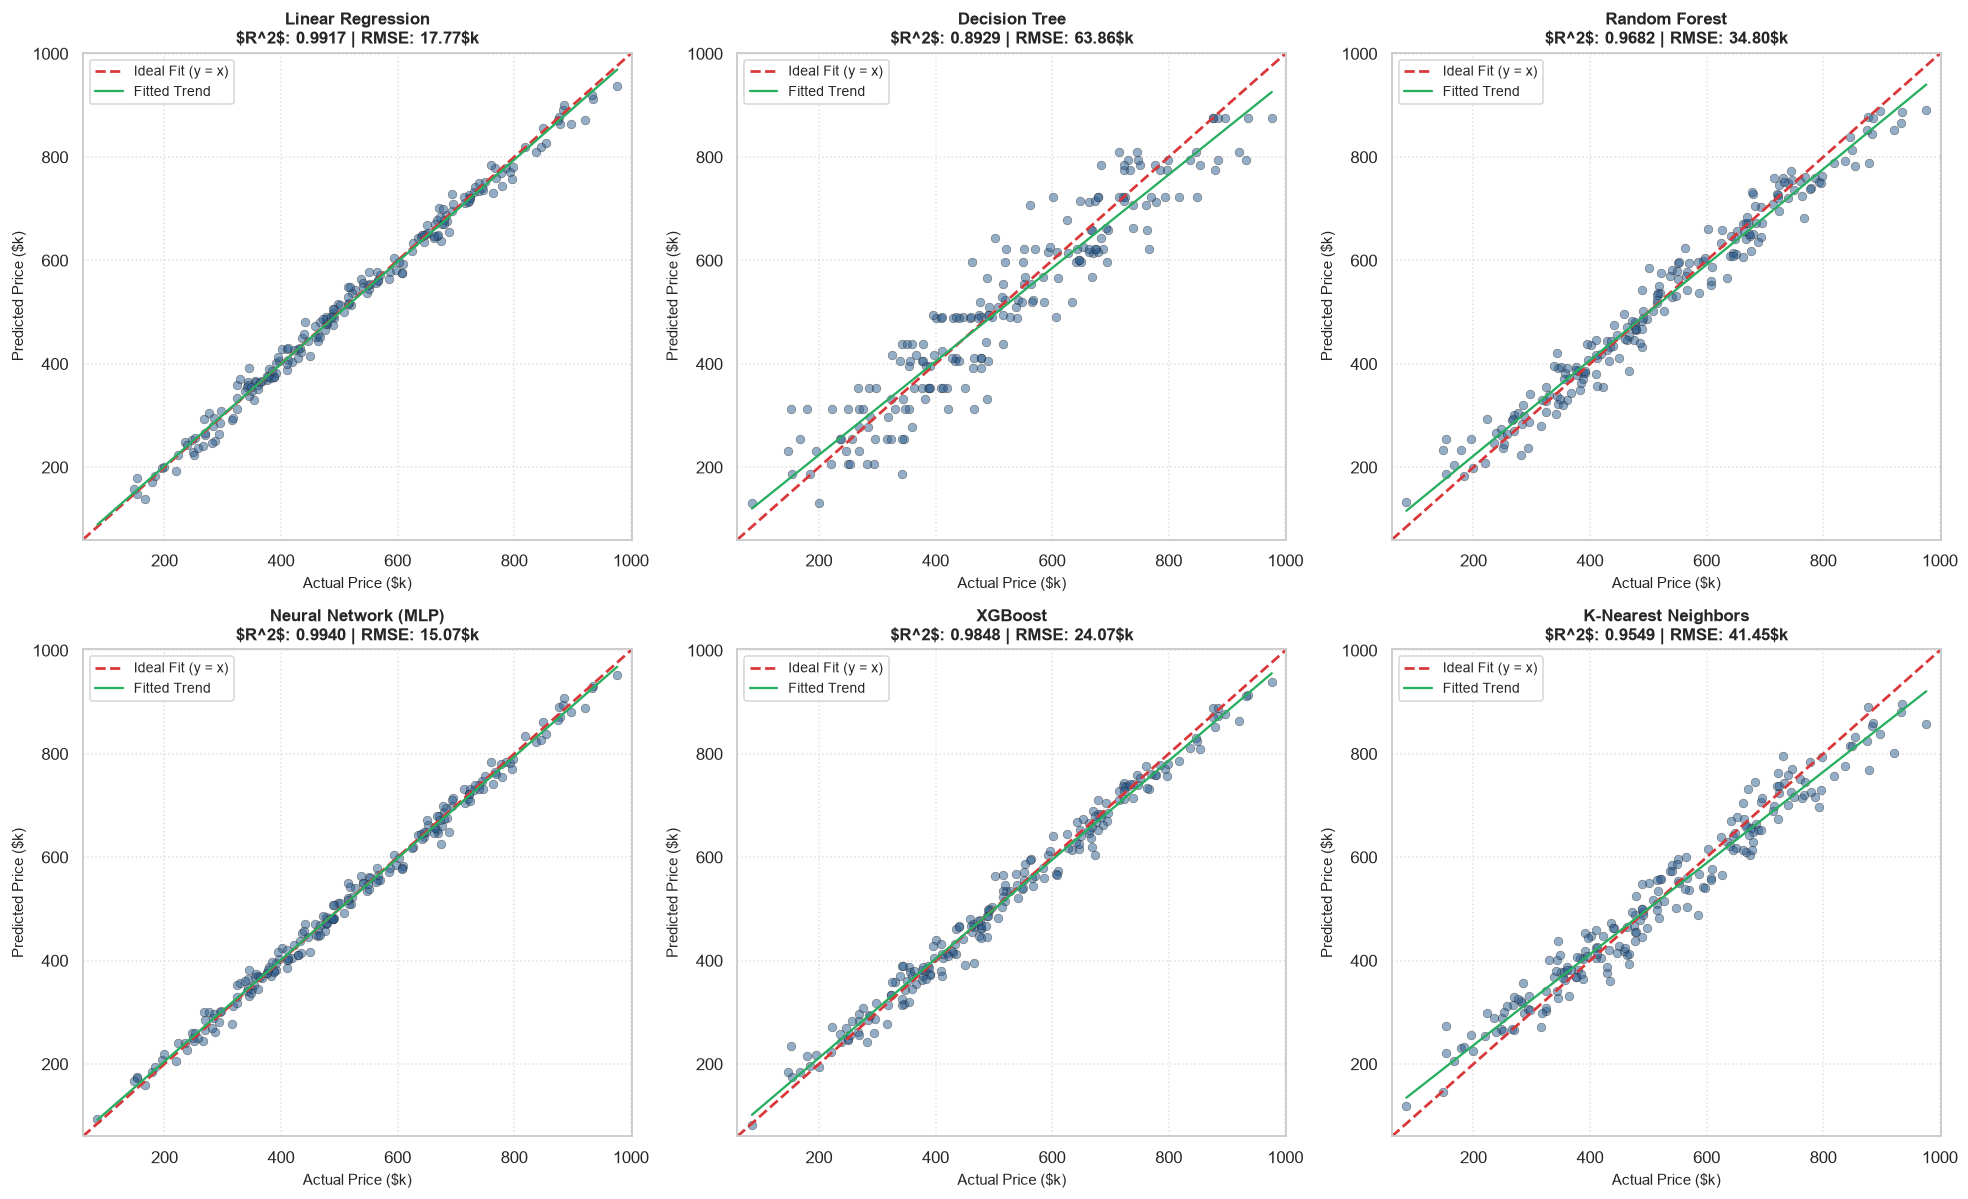

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()
y_min, y_max = y_test.min() - 25, y_test.max() + 25

for idx, (name, y_pred) in enumerate(predictions.items()):
    ax = axes[idx]
    ax.scatter(y_test, y_pred, alpha=0.50, edgecolors='k', linewidth=0.4, color='#2b5c8f', s=32)
    ax.plot([y_min, y_max], [y_min, y_max], color='#d9383a', linestyle='--', linewidth=1.8, label='Ideal Fit (y = x)')
    
    # Empirical trend
    slope, intercept = np.polyfit(y_test, y_pred, 1)
    ax.plot(np.sort(y_test), slope * np.sort(y_test) + intercept, color='#27ae60', linestyle='-', linewidth=1.5, label='Fitted Trend')
    
    m_row = metrics_df[metrics_df['Algorithm'] == name].iloc[0]
    ax.set_title(f"{name}\n$R^2$: {m_row['R2 Score']:.4f} | RMSE: {m_row['RMSE ($k)']:.2f}$k", fontsize=11, fontweight='bold')
    ax.set_xlabel('Actual Price ($k)', fontsize=10)
    ax.set_ylabel('Predicted Price ($k)', fontsize=10)
    ax.set_xlim(y_min, y_max)
    ax.set_ylim(y_min, y_max)
    ax.legend(loc='upper left', fontsize=9)
    ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

## 5. Visualization: Residual Error Distributions
Evaluating normality and dispersion of residual errors ($e_i = y_i - \hat{y}_i$).

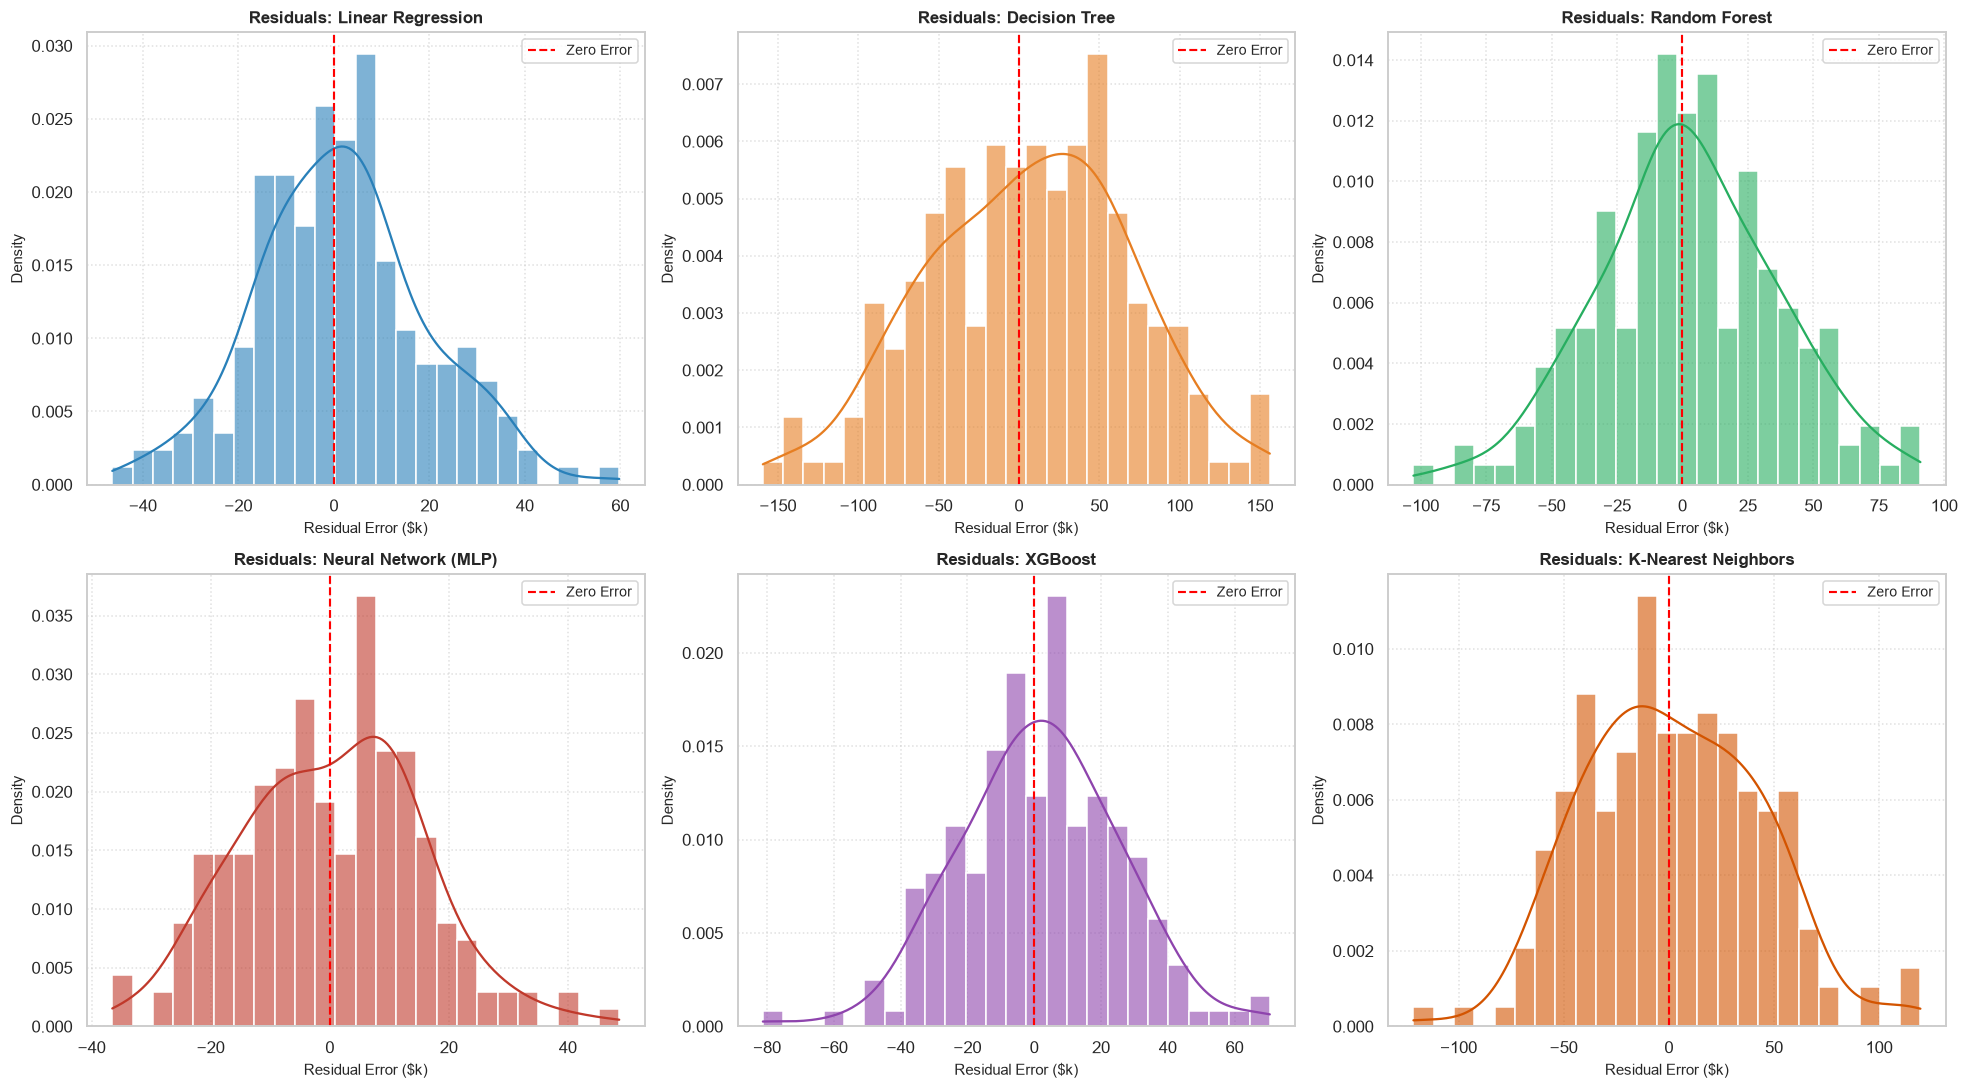

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
palette = ['#2980b9', '#e67e22', '#27ae60', '#c0392b', '#8e44ad', '#d35400']

for idx, (name, y_pred) in enumerate(predictions.items()):
    ax = axes[idx]
    res = y_test - y_pred
    sns.histplot(res, kde=True, ax=ax, color=palette[idx], stat='density', bins=25, alpha=0.6)
    ax.axvline(0, color='red', linestyle='--', linewidth=1.4, label='Zero Error')
    ax.set_title(f'Residuals: {name}', fontsize=11, fontweight='bold')
    ax.set_xlabel('Residual Error ($k)', fontsize=10)
    ax.set_ylabel('Density', fontsize=10)
    ax.legend(loc='upper right', fontsize=9)
    ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

## 6. Visualization: Performance Metrics Comparison
Comparative side-by-side assessment of error metrics (MAE & RMSE) and explanatory power ($R^2$).

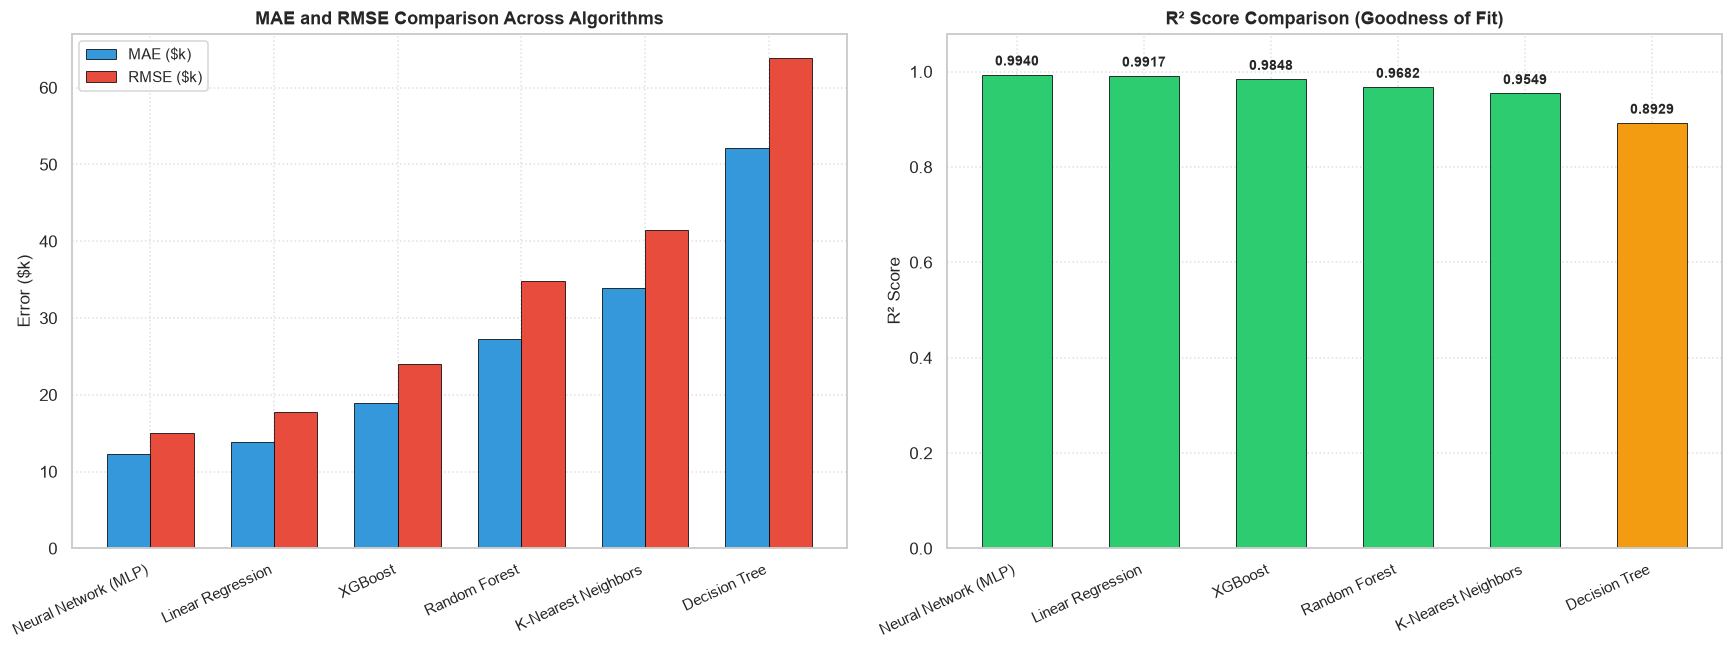

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
order_df = metrics_df.copy()
x_indices = np.arange(len(order_df))
bar_width = 0.35

# Subplot 1: MAE vs RMSE
ax1.bar(x_indices - bar_width/2, order_df['MAE ($k)'], width=bar_width, label='MAE ($k)', color='#3498db', edgecolor='black', linewidth=0.5)
ax1.bar(x_indices + bar_width/2, order_df['RMSE ($k)'], width=bar_width, label='RMSE ($k)', color='#e74c3c', edgecolor='black', linewidth=0.5)
ax1.set_xticks(x_indices)
ax1.set_xticklabels(order_df['Algorithm'], rotation=25, ha='right', fontsize=10)
ax1.set_ylabel('Error ($k)', fontsize=11)
ax1.set_title('MAE and RMSE Comparison Across Algorithms', fontsize=12, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, linestyle=':', alpha=0.6)

# Subplot 2: R^2 Score
colors_r2 = ['#2ecc71' if score >= 0.95 else '#f39c12' if score >= 0.85 else '#e74c3c' for score in order_df['R2 Score']]
bars = ax2.bar(x_indices, order_df['R2 Score'], color=colors_r2, edgecolor='black', linewidth=0.5, width=0.55)
ax2.set_xticks(x_indices)
ax2.set_xticklabels(order_df['Algorithm'], rotation=25, ha='right', fontsize=10)
ax2.set_ylabel('R² Score', fontsize=11)
ax2.set_title('R² Score Comparison (Goodness of Fit)', fontsize=12, fontweight='bold')
ax2.set_ylim(0, 1.08)
for bar in bars:
    h = bar.get_height()
    ax2.annotate(f'{h:.4f}',
                 xy=(bar.get_x() + bar.get_width() / 2, h),
                 xytext=(0, 4),
                 textcoords='offset points',
                 ha='center', va='bottom', fontsize=9, fontweight='bold')
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

## 7. Residual Diagnostics and Error Summary Statistics
Tabulating bias (mean residual error), standard deviation of residuals, and extreme deviation bounds.

In [9]:
res_stats = []
for name, y_pred in predictions.items():
    e = y_test - y_pred
    res_stats.append({
        'Algorithm': name,
        'Mean Error (Bias)': round(float(np.mean(e)), 4),
        'Std Dev of Residuals': round(float(np.std(e)), 4),
        'Min Residual': round(float(np.min(e)), 4),
        'Max Residual': round(float(np.max(e)), 4)
    })

res_df = pd.DataFrame(res_stats).merge(metrics_df[['Algorithm', 'Rank']], on='Algorithm').sort_values('Rank')
display(res_df[['Rank', 'Algorithm', 'Mean Error (Bias)', 'Std Dev of Residuals', 'Min Residual', 'Max Residual']])

,Rank,Algorithm,Mean Error (Bias),Std Dev of Residuals,Min Residual,Max Residual
3,1,Neural Network (MLP),0.4844,15.0622,-36.5274,48.6322
0,2,Linear Regression,1.5730,17.6991,-46.3924,59.7621
4,3,XGBoost,1.6966,24.0082,-81.2247,70.5454
2,4,Random Forest,1.9886,34.7465,-102.7346,90.8925
5,5,K-Nearest Neighbors,1.5895,41.4171,-121.4331,119.6128
1,6,Decision Tree,6.8900,63.4823,-159.3250,156.1473
